# Map of Catalonia: forest hectares burned per municipality (2011-2024)
## Jesús Ruiz Angorrilla
In this notebook we join the fires table with the municipality outlines and map the total forest area burned in each municipality between 2011 and 2024.

**Data** (both in `../data/`, see the README there for sources and licences):
- Forest fires in Catalonia, 2011-2024 (CSV): one row per fire, with its municipality code and the hectares burned.
- Municipality outlines of Catalonia (ICGC, 1:1,000,000, JSON).

**Steps**
1. Read the fires table and sum the forest hectares burned (`HAFORESTAL`) per municipality.
2. Read the outlines and join both tables by municipality code.
3. Draw a static map with a logarithmic colour scale, since most municipalities burn very little and a few burn a huge amount. Municipalities with no recorded fires (0 ha) are drawn in light grey.
4. Draw an interactive map with the same colour scale and a tooltip showing the municipality name and its burned hectares.
5. Plot a bar chart of the 10 municipalities with the most hectares burned.

**Output**: the static map is saved as `../figures/Jesus/fires_map_municipalities.png`.

## 0) Libraries

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch

## 1) Read and prepare the fires table

In [ ]:
# Read the CSV; I tell pandas that the dot separates thousands and the comma marks decimals because of the format of the data
fires = pd.read_csv("../data/Incendis_forestals_a_Catalunya._Anys_2011-2024_20261116.csv",decimal=",", thousands=".",)
# The municipality code in the CSV has no leading zero (80018) but in the map it does (080018)
# I turn it into text and pad it with zeros on the left until it has 6 digits in a new column
fires["code"] = fires["CODI MUNICIPI"].astype(str).str.zfill(6)

# Each row is one fire, but I want one total per municipality so I group by municipality and add up the burned forest hectares
total = fires.groupby("code")["HAFORESTAL"].sum().reset_index()

# Give the summed column a clearer name
total = total.rename(columns={"HAFORESTAL": "ha_burned"})

## 2) Read the map and join it with the data

In [3]:
# Read the file with the municipality outlines
map_cat = gpd.read_file("../data/divisions-administratives-v2r1-municipis-1000000-20250730.json")

# Convert to Catalonia's coordinate system (EPSG:25831) in meters so the map is not distorted
map_cat = map_cat.to_crs(25831)

# Join the map with my totals using the municipality code
# how="left" keeps every municipality even if it had no fires; validate prevents duplicated rows
map_cat = map_cat.merge(total, left_on="CODIMUNI", right_on="code", how="left", validate="one_to_one")

# Municipalities with no fires (or 0 ha) are marked as "empty" (NaN) so they are drawn in grey
map_cat["ha_burned"] = map_cat["ha_burned"].replace(0, float("nan"))

DataSourceError: ../data/divisions-administratives-v2r1-municipis-1000000-20250730.json: No such file or directory

## 3) Draw the map

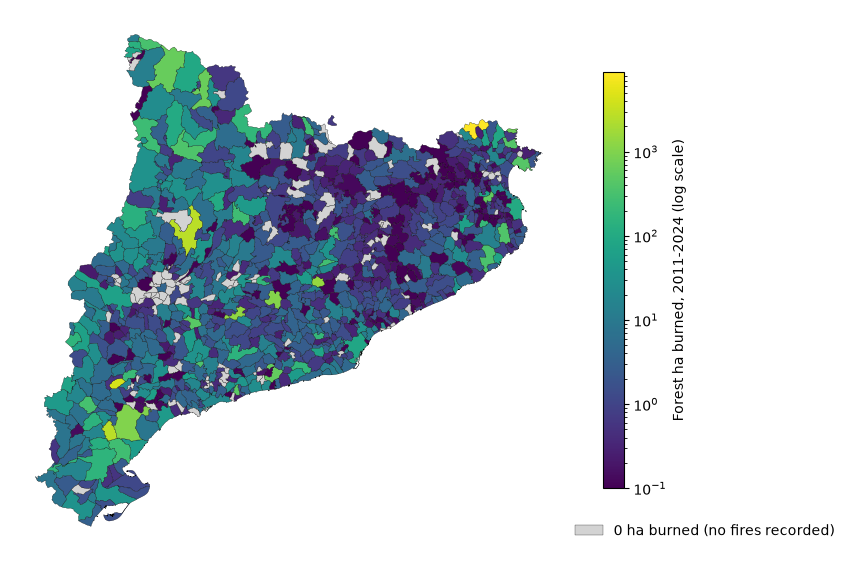

In [34]:
fig, ax = plt.subplots(figsize=(9, 9))

# Draw the map, colouring each municipality by its burned hectares
map_cat.plot(
    column="ha_burned",                  
    cmap="viridis",
    norm=LogNorm(vmin=0.1, vmax=map_cat["ha_burned"].max()),  # log scale: most municipalities burn very little and a few burn a huge amount
    legend=True,                          # add the colour bar
    legend_kwds={"label": "Forest ha burned, 2011-2024 (log scale)", "shrink": 0.6},  # colour bar text and size
    missing_kwds={"color": "lightgrey"},  # municipalities with no data are drawn in light grey
    edgecolor="black",                    # white border between municipalities
    linewidth=0.2,                        # very thin border so it does not hide the colours
    ax=ax,                                # tell it which area to draw on
)

# Extra legend entry explaining the light grey areas
grey_patch = Patch(facecolor="lightgrey", edgecolor="black", linewidth=0.2, label="0 ha burned (no fires recorded)")
ax.legend(handles=[grey_patch], loc="lower right", bbox_to_anchor=(1.5, 0), frameon=False)
ax.set_axis_off() # we don't need axis
fig.savefig("../figures/Jesus/fires_map_municipalities.png", dpi=200, bbox_inches="tight")
plt.show()

## 4) Draw the interactive map

In [36]:
import folium
import branca.colormap as cm
import numpy as np
import pandas as pd
from folium.plugins import Search

# Convert the map
map_interactive = map_cat.to_crs(epsg=4326).copy()

# Largest fire of each municipality (date and forest ha burned)
fires["date"] = pd.to_datetime(fires["DATA INCENDI"], dayfirst=True)
biggest = fires.loc[fires.groupby("code")["HAFORESTAL"].idxmax(), ["code", "date", "HAFORESTAL"]]
biggest = biggest.rename(columns={"code": "CODIMUNI", "date": "biggest_date", "HAFORESTAL": "biggest_ha"})

# Municipalities whose fires burned 0 forest ha have no "largest fire" to show
biggest = biggest[biggest["biggest_ha"] > 0]

# Text versions for the tooltip
biggest["biggest_date_tooltip"] = biggest["biggest_date"].dt.strftime("%d/%m/%Y")
biggest["biggest_ha_tooltip"] = biggest["biggest_ha"].apply(lambda x: f"{x:g} ha")

# Join with the map by municipality code; "-" where there are no fires
map_interactive = map_interactive.merge(
    biggest[["CODIMUNI", "biggest_date_tooltip", "biggest_ha_tooltip"]],
    on="CODIMUNI", how="left", validate="one_to_one",
)
map_interactive[["biggest_date_tooltip", "biggest_ha_tooltip"]] = (
    map_interactive[["biggest_date_tooltip", "biggest_ha_tooltip"]].fillna("-")
)

# Create a colour scale in logarithmic scale
vmin = 0.1
vmax = map_interactive["ha_burned"].max()

# Viridis colour palette
colors = ["#440154", "#414487", "#2a788e", "#22a884", "#7ad151", "#fde725"]

colormap = cm.LinearColormap(
    colors=colors,
    vmin=np.log10(vmin),
    vmax=np.log10(vmax),
    caption="Forest ha burned, 2011-2024 (log scale)"
)

# Create the interactive map
m = folium.Map(location=[41.8, 1.5], zoom_start=8, tiles="OpenStreetMap", control_scale=True)

# Create a tooltip column
map_interactive["ha_burned_tooltip"] = (
    map_interactive["ha_burned"]
    .apply(lambda x: "0" if pd.isna(x) or x == 0 else f"{x:g}")
)

# Municipality colours
def style_function(feature):
    value = feature["properties"]["ha_burned"]

    # Grey for municipalities with 0 or NaN
    if value is None or pd.isna(value) or value == 0:
        color = "lightgrey"
    else:
        color = colormap(np.log10(max(value, vmin)))

    return {
        "fillColor": color,
        "color": "black",
        "weight": 0.35,
        "fillOpacity": 0.85
    }

# Municipality borders and hover information
municipalities_layer = folium.GeoJson(
    map_interactive,
    name="Forest fires by municipality",
    style_function=style_function,
    highlight_function=lambda feature: {
        "weight": 2,
        "color": "#222222",
        "fillOpacity": 1
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["NOMMUNI", "ha_burned_tooltip", "biggest_ha_tooltip", "biggest_date_tooltip"],
        aliases=["Municipality:", "Forest ha burned:", "Largest fire:", "Date of largest fire:"],
        localize=True,
        sticky=True,
        labels=True,
        style="""
            background-color: white;
            color: #333333;
            font-family: Arial;
            font-size: 13px;
            padding: 10px;
            border: 2px solid #440154;
            border-radius: 6px;
        """
    )
).add_to(m)

# Search box to find a municipality by name
Search(
    layer=municipalities_layer,
    search_label="NOMMUNI",              # property to search in
    geom_type="Polygon",
    placeholder="Search municipality",
    collapsed=False,                     # keep the search box open
    search_zoom=11,                      # zoom level when a municipality is found
    initial=False,                       # match anywhere in the name, not only at the start
    position="topleft",
).add_to(m)

# Manual legend with real hectare values
ticks = [
    t for t in [0.1, 1, 10, 100, 1000, 10000, 100000]
    if vmin <= t <= vmax
]

# Calculate tick positions using logarithmic scale
tick_html = ""

for t in ticks:
    pos = (
        (np.log10(t) - np.log10(vmin)) /
        (np.log10(vmax) - np.log10(vmin)) * 100
    )

    tick_html += f'''
    <div style="position: absolute;
                left: {pos}%;
                transform: translateX(-50%);">
        {t:g}
    </div>
    '''

# Legend
legend_html = f"""
<div style="position: fixed; bottom: 30px; right: 10px; z-index: 9999;
            background-color: white; padding: 10px 15px 8px 15px;
            border-radius: 6px; box-shadow: 0 0 6px rgba(0,0,0,0.3);
            font-family: Arial; font-size: 12px; width: 300px;">

    <div style="margin-bottom: 6px;">
        Forest ha burned, 2011-2024 (log scale)
    </div>

    <div style="height: 12px;
                background: linear-gradient(to right, {', '.join(colors)});">
    </div>

    <div style="position: relative; height: 18px; margin-top: 3px;">
        {tick_html}
    </div>

    <div style="margin-top: 5px; color: #666;">
        <span style="display:inline-block; width:10px; height:10px;
                     background:lightgrey; margin-right:4px;">
        </span>
        0 ha burned
    </div>

</div>
"""

# Add colour legend
m.get_root().html.add_child(folium.Element(legend_html))

# Layer control
folium.LayerControl(collapsed=True).add_to(m)

# Display map
m

## 5) Draw a histogram of the municipalities with the most hectares burned


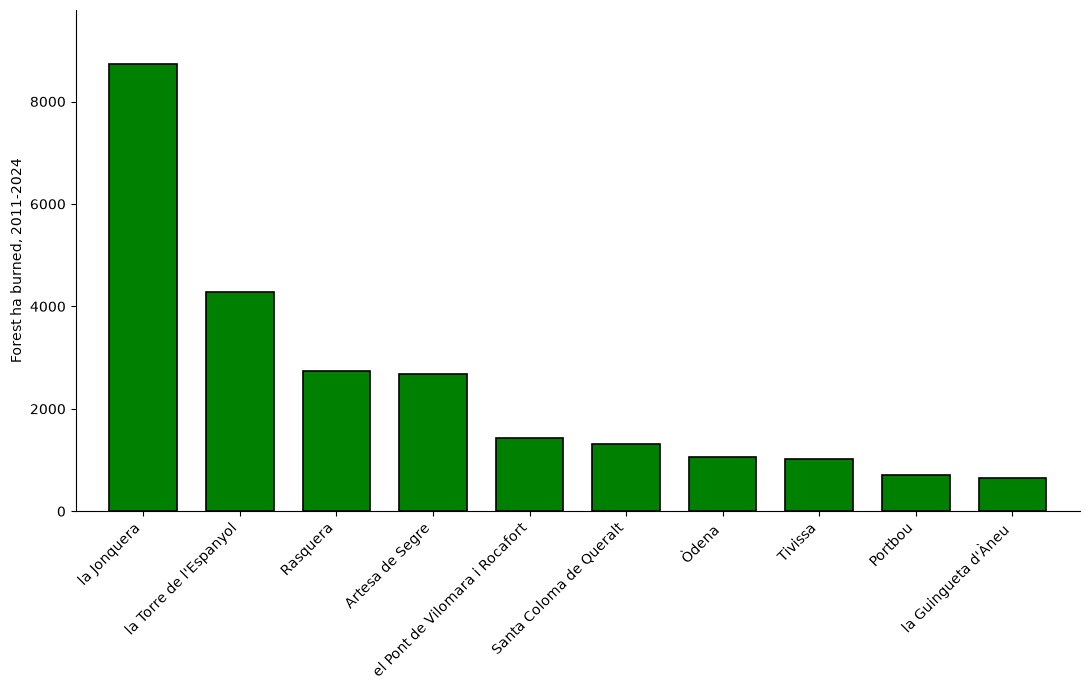

In [30]:
top = map_cat.nlargest(10, "ha_burned").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 7))

ax.bar(range(len(top)), top["ha_burned"], color="green", edgecolor="black", linewidth=1.2, width=0.7)

ax.set_xticks(range(len(top)))
ax.set_xticklabels(top["NOMMUNI"], rotation=45, ha="right")
ax.set_xlim(-0.7, len(top) - 0.3)
ax.set_ylim(0, top["ha_burned"].max() * 1.12)
ax.set_ylabel("Forest ha burned, 2011-2024")
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig("../figures/Jesus/top_10_municipalities.png", dpi=200, bbox_inches="tight")
plt.show()